# Lesson 17. When one splat cannot do the job

[Course plan](../../README.md)

The target has two blue beads with a pale gap between them. The model has a single broad splat and an almost transparent speck off to the side. We can move the broad splat or fade it. Its horizontal slice still has one peak where the target has two. Sometimes the next useful move is a change to the list of Gaussians itself.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "en"

## One starting point, several possible moves

The camera, color, and background stay fixed. The target is on the left, the model on the right. Separate operations can copy a selected splat, replace it with two children, remove faint splats, or reduce all opacities together. Returning to the starting scene lets us compare these moves from a common reference. An ordinary gradient step moves centers horizontally and changes their opacity.

Each comparison has three different readings. MSE measures color discrepancies across 33 × 33 pixels. Splat count measures the length of the list. The byte count includes just the numerical scene parameters stored in float32. An edit that takes more space and makes the image worse is an informative outcome too.

A square on both images marks the sampled pixel. The column slider moves it along row 16. It starts in the gap, where the red-channel difference is about −0.463.

In [2]:
display(demo.experiment(17, "en"))

## A white gap belongs in the middle

The previous fit began with a useful clue. Even its poor initial model already had the right number of objects. Here the number of independently movable details is itself unknown. From across the room a blue cloud might look fairly similar to two beads. A horizontal scan through both centers gives us three specific locations for comparing colors.

The camera center is at zero and its focal length is 42 pixels. Both target centers have depth 4 m, at $X=-0.54$ and $X=0.42$ m. Their projected centers fall at columns $16+42(-0.54)/4=10.33$ and $16+42(0.42)/4=20.41$. Both have $Y=0$, so row 16 passes through them. Columns 10, 16 and 20 serve three different purposes. The first and last fall near bead centers. The middle one lands in the gap. In NumPy the indexing order is row, column, channel. For instance, `image[16, 10, 0]` is red intensity in the left bead. Red intensity on the white background is one. Blue paint takes away a lot of red, so each bead appears as a **valley** in a graph of the red channel.

| Red channel on row 16 | Left center | Gap | Right center |
|---|---:|---:|---:|
| Two target beads | 0.215 | 0.806 | 0.219 |
| Initial model | 0.453 | 0.344 | 0.531 |

The left and right parts need to get darker while the middle needs to get lighter. The middle of the broad splat is currently its darkest part. Increasing opacity everywhere would darken both ends while worsening the gap. Pulling the whole splat to the right would pay for an improvement on one bead with a mistake on the other. The three numbers reveal the **shape** of the error more clearly than one average. The figure keeps the entire row. The three marked columns help read the profiles even where the lines nearly overlap.

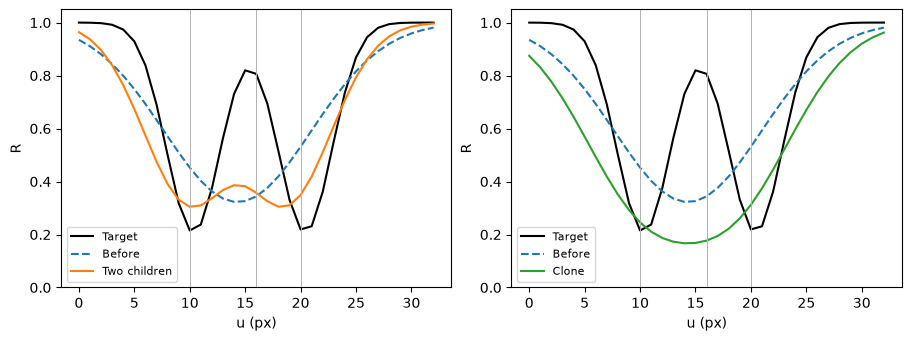

In [3]:
camera = sr.translated_camera(0, focal=42)
start = sr.density_scene()
cases = [sr.density_scene(True), start, sr.density_edit(start, "split"), sr.density_edit(start, "clone")]
names = (["Образец", "До", "Два ребёнка", "Клон"] if lang == "ru"
         else ["Target", "Before", "Two children", "Clone"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), constrained_layout=True)
for ax, indices in zip(axes, [(0, 1, 2), (0, 1, 3)]):
    for i in indices:
        image = sr.render_scene(cases[i], camera, 33, 33)
        ax.plot(image[16, :, 0], ["k-", "C0--", "C1-", "C2-"][i], label=names[i])
    for u in [10, 16, 20]:
        ax.axvline(u,color=".7",lw=.7)
    ax.set(xlabel="u (px)", ylabel="R", ylim=(0,1.05)); ax.legend(fontsize=8)
plt.show()

## A step inside the list

Initially the list holds two splats. The broad one has $x=-0.16$, horizontal scale $s_x=0.63$, and center opacity $o=0.77$. A small shift changes the frame's RGB and its error. For the two derivatives we take two neighboring measurements apiece, starting each from the same original state as in the previous lesson. We get $g_x\approx-0.00304635$ MSE per unit of length and $g_o\approx0.00834045$ per unit of opacity.

At learning rate $\eta=3$, the new coordinate is $x'=-0.16-3(-0.00304635)\approx-0.15086$. The new opacity is $o'=0.77-3(0.00834045)\approx0.74498$. The splat moves right and becomes a touch paler on white. The small splat gets its own two derivatives. After the simultaneous update MSE falls from $0.00467723$ to $0.00446188$. Indices 0 and 1 still refer to the same two splats. The gradient of a value in row 0 cannot create row 2.

In [4]:
initial = sr.density_scene()
print(np.round(sr.density_gradients(initial), 7))
updated = sr.density_step(initial)
print(updated["splats"][0]["center"], updated["splats"][0]["opacity"])
assert len(initial["splats"]) == len(updated["splats"]) == 2
assert sr.density_loss(updated) < sr.density_loss(initial)

[[-3.0463e-03  8.3405e-03]
 [ 4.5300e-05 -5.5900e-05]]
[-0.1508609595795733, 0, 4] 0.7449786379339152


### Can another center update solve it?

This is an easy place to misdiagnose the fit. MSE went down after the first step. Does that guarantee a white gap after enough steps? The size of the first improvement cannot tell us. Our experiment only allows a horizontal center and an opacity update for each splat. Its scales stay fixed. Both center gradients and both opacity gradients are measured **before** editing any row. Otherwise the next derivative would see a different scene and the collection of gradients would no longer describe the same starting image.

The broad splat's opacity derivative is about 0.00834 per unit of $o$. A small opacity increase of 0.001 would therefore raise error by about $0.00834\cdot0.001=0.00000834$. A decrease in $o$ helps on average even though the left bead currently needs more blue. It is a compromise over all pixels, including the background. After twelve ordinary steps the same model's error is about 0.004002. Parameter motion helped. The shapes a single wide bell can take remain limited.

The second, tiny splat deserves a closer look too. Technically it already supplies a second peak. It starts almost transparent and well above the two beads. The only available center movement is horizontal, so it cannot drop onto their row. Its initial horizontal gradient is almost seventy times weaker than the big splat's. Free vertical movement, independent scales and a different initialization would change the problem. This particular run can teach us how the operations work. It would be odd to conclude that two freely adjustable Gaussians cannot represent two beads at all. Two Gaussians are precisely what made the target.

## A clone darkens the image. A split changes its shape

A **clone** appends a copy of the center, shape, color, and opacity. At the original splat center $\alpha=0.77$, so $1-0.77=0.23$ of the background passed through. Two identical layers pass $0.23\cdot0.23=0.0529$, making their combined opacity $1-0.0529=0.9471$. Identical coordinates therefore change the image. The oversized dark blue region raises MSE to $0.01214659$. Future steps can move the two copies independently.

A **split** removes the broad parent and inserts two children. For a repeatable example we place them symmetrically along the horizontal axis. Their offset is $0.65\cdot0.63=0.4095$, giving centers $-0.16-0.4095=-0.5695$ and $-0.16+0.4095=0.2495$. Each of their three scales is divided by $1.6$. For instance the horizontal one becomes $0.63/1.6=0.39375$. They inherit the parent's color and $o$. Two peaks begin to emerge and MSE becomes $0.00347211$. For a different target or starting splat this same operation can make the image worse.

Both edits grew the list from two rows to three. After cloning it contains the parent and its exact copy. After splitting the parent is gone, leaving two displaced splats and the original speck.

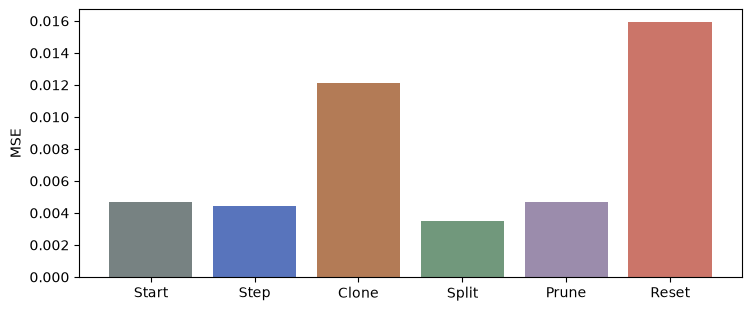

In [5]:
fig = demo.density_chart("en")
display(fig)
plt.close(fig)

### Can opacity be shared without a jump?

Two original-strength copies cut off most of the background. A tempting alternative is to give each one half the old opacity. At the center this means $0.77/2=0.385$. The remaining background becomes $(1-0.385)^2=0.378225$, versus 0.23 before the copy. Translucent layers also occlude one another. Halving one number does not preserve the final color.

At the center of coincident splats we can work backward. The two equal layers should leave exactly the old transmittance $T=0.23$. With $a$ denoting the new opacity of each layer, this gives

$$
\begin{aligned}
(1-a)(1-a)&=0.23,\\
1-a&=\sqrt{0.23}\approx0.47958,\\
a&=1-0.47958\approx0.52042.
\end{aligned}
$$

The positive root follows from transmittance being a fraction between zero and one. This might seem to finish the calculation. But the center is just one address. At a distance where the Gaussian weight falls to one half, the old model gives $\alpha=0.77\cdot0.5=0.385$. The two layers together now cover $1-(1-0.52042\cdot0.5)^2\approx0.4527$. Their edges are still darker, even though the center has been matched exactly. Even careful duplication alters the profile before the optimizer makes another step.

The difference came from multiplying two transmittances. There is no constant opacity adjustment that reproduces the old soft footprint everywhere while keeping two identical child shapes. A split also changes centers and scales. Immediately after a split, red in the gap still sits near 0.357 versus 0.806 in the target. Now the two children have independent directions in which to move. What changed is the ability of **subsequent** steps to improve the shape, something that shows up only once fitting resumes.

In [6]:
parent_o = .77
child_o = 1 - np.sqrt(1-parent_o)
for w in (1, .5, .1, 0):
    old = parent_o*w
    pair = 1 - (1-child_o*w)**2
    print(f"w={w:.1f}   old={old:.5f}   pair={pair:.5f}   Δ={pair-old:+.5f}")

w=1.0   old=0.77000   pair=0.77000   Δ=+0.00000
w=0.5   old=0.38500   pair=0.45271   Δ=+0.06771
w=0.1   old=0.07700   pair=0.10138   Δ=+0.02438
w=0.0   old=0.00000   pair=0.00000   Δ=+0.00000


## Pruning and resetting have different effects

**Pruning** removes a splat altogether. Our threshold $0.03$ applies to center opacity. The speck has $o=0.015<0.03$, so it disappears. The large splat remains useful. The list shrinks and the error stays close to its initial value, at $0.00467882$. It actually **increased** slightly. A tiny contribution still has an effect.

An **opacity reset** leaves centers and shapes in place. The new value $o'=\min(o,0.01)$ is the smaller of the old $o$ and one hundredth. For instance $0.77$ becomes $0.01$, whereas $0.004$ stays $0.004$. When the splats are faint, more light passes through and a hidden layer has a chance to contribute. Optimization can build useful opacities back up. Immediately after resetting, the image is almost white and MSE is $0.01592582$. Applying the pruning threshold of $0.03$ at this moment would remove every splat. Both order and timing matter in a full training run.

In [7]:
for action in ("clone","split","prune","reset"):
    scene = sr.density_edit(initial, action)
    n = len(scene["splats"])
    print(f"{action:6s} N={n}, bytes={56*n}, MSE={sr.density_loss(scene):.8f}")
assert len(sr.density_edit(sr.density_edit(initial, "reset"), "prune")["splats"]) == 0

clone  N=3, bytes=168, MSE=0.01214659
split  N=3, bytes=168, MSE=0.00347211
prune  N=1, bytes=56, MSE=0.00467882
reset  N=2, bytes=112, MSE=0.01592582


### Pruning seen by a different camera

The crumb has opacity 0.015. Even at its own center it receives at most that fraction of the color. If a foreground layer leaves only one tenth of the light, its pixel weight is at most $0.1\cdot0.015=0.0015$. This gives a reason to test removal, but it does not tell us its cost for the **whole image**. A large faint splat touches many pixels. A small one might sit on a thin high-contrast detail. A new camera position can also reveal a footprint that used to hide behind a nearer layer.

We can compare the original, an immediate clone, an immediate split and a removal at two camera positions. The bead geometry is known, so each target view can be produced independently. The edits were chosen from the frontal image. Our second camera moves to $+0.6$ m with the same focal length and orientation. It checks a decision and never contributes to the gradients. With pruning, frontal error rises from about 0.00467723 to 0.00467882. At the other camera it goes from 0.00420203 to 0.00420206. Rounding to three decimals would hide the difference entirely. The two scenes still differ and one splat's parameter cost really did go away.

Another legitimate choice is to include storage in the decision. Suppose we add a charge $\lambda N$ to MSE when selecting a scene. Here $N$ is the integer splat count and $\lambda$ is a charge measured in units of mean error per additional row. This gives a score $J=L+\lambda N$. It does not create any new pixel. It defines what “better” means for this particular comparison. An immediate split gains $0.00467723-0.00347211=0.00120512$ in MSE at the cost of one extra row. A charge of 0.0005 leaves a net advantage for the split. At a charge of 0.002 the original model wins. This calculation compares two completed states. A budget of twelve more training steps calls for a fresh comparison after those steps.

The original work changes density using an accumulated signal and rules for size and opacity. Here the row charge serves only to make our choice explicit. The derivative of $J$ with respect to a coordinate at a fixed row count equals the derivative of $L$. Adding the constant $\lambda N$ gives the existing center no direction in which to create a neighbor.

In [8]:
held_camera = sr.translated_camera(.6, focal=42)
held_target = sr.render_scene(sr.density_scene(True), held_camera, 33, 33)
for action in ("unchanged", "clone", "split", "prune", "reset"):
    candidate = initial if action == "unchanged" else sr.density_edit(initial, action)
    held_frame = sr.render_scene(candidate, held_camera, 33, 33)
    held_mse = np.mean((held_frame-held_target)**2)
    before_loss = sr.density_loss(candidate)
    fitted = candidate
    for _ in range(12):
        fitted = sr.density_step(fitted)
    print(f"{action:9} N={len(candidate['splats'])}  train={before_loss:.8f}  "
          f"held={held_mse:.8f}  train@12={sr.density_loss(fitted):.8f}")

unchanged N=2  train=0.00467723  held=0.00420203  train@12=0.00400165


clone     N=3  train=0.01214659  held=0.01042208  train@12=0.00407204


split     N=3  train=0.00347211  held=0.00310032  train@12=0.00282129


prune     N=1  train=0.00467882  held=0.00420206  train@12=0.00400429
reset     N=2  train=0.01592582  held=0.01600684  train@12=0.00411495


## How a training loop makes the decision

In one adaptive pass of the experiment we first compute all gradients in the old scene. Any splat with $o<0.03$ is marked for removal. For the others we compare the magnitude of their horizontal gradient with $0.001$. For the broad splat $|-0.00304635|>0.001$. This flags an area where moving the center can appreciably change the loss. It measures sensitivity to a shift, with no guarantee that this is where a detail is missing.

Now we need a copy or two children. In this experiment a horizontal scale above $0.32$ counts as broad. Since $0.63>0.32$, the splat is split. A sufficiently narrow one with the same strong signal would be cloned. A budget of 16 splats keeps each step easy to inspect. After the first adaptive pass the broad splat has become two and the faint speck is gone, so the count is two again. The MSE is different, about $0.00348773$. A splat counter alone would miss this restructuring.

The original 3DGS implementation accumulates a signal for **visible** splats over training steps. It takes lengths of the two-component screen-center gradients and averages them over observations. Size is compared with scene extent. A split samples children around the parent's center using its shape and orientation. The code can also prune excessively large footprints. Our single-camera version uses the derivative along the world x axis, deterministic child offsets, and explicit controls. The example thresholds belong to its particular coordinates and loss. [Algorithm in the paper](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) and [parameter operations in the reference implementation](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/gaussian_model.py).

In [9]:
adaptive = sr.density_pass(initial)
print([(s["center"][0],s["scales"][0],s["opacity"]) for s in adaptive["splats"]])
assert len(adaptive["splats"]) == len(initial["splats"])
assert sr.density_loss(adaptive) < sr.density_loss(initial)
for _ in range(8):
    adaptive = sr.density_step(adaptive)
print("8 steps:", sr.density_loss(adaptive))

[(-0.5695, 0.39375, 0.77), (0.24950000000000003, 0.39375, 0.77)]


8 steps: 0.0028990938514448354


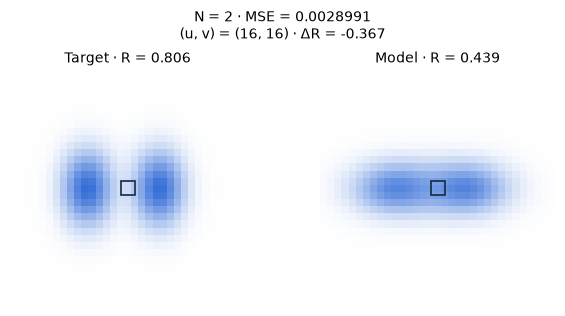

In [10]:
fig = demo.density_figure("en", operation="adaptive", steps=8)
display(fig)
plt.close(fig)

## Experiments and worked answers

How much memory did a clone add? Why can the change in total GPU memory use not be read directly from that number?

<details><summary>Worked answer</summary>

A splat stores three coordinates, three scales, four quaternion components, three color channels, and an opacity. That is $3+3+4+3+1=14$ numbers. One float32 occupies $32/8=4$ bytes. A clone adds $14\cdot4=56$ bytes of parameter payload. Two splats take 112 bytes and three take 168. A full model adds SH coefficients, gradients, optimizer state, tile lists, and temporary images. Text JSON also contains characters and keys. Here we measure exactly the numerical payload of the chosen representation.

</details>

### A copy or a second visible detail?

When two equal layers of the same color coincide in all coordinates, why does the center darken before two separate beads appear?

<details><summary>Reading the profile</summary>

With identical shapes the factor $w$ at any given pixel is shared. The covered fraction $1-(1-ow)^2$ increases with $w$ throughout the interval from zero to one. Wherever the single splat had its maximum, the pair retains a maximum at the same position. It is now higher. Two spatially separate peaks require different positions, different shapes, or later fitting that breaks the coincidence. In a red-channel profile this extra blue coverage looks like a deeper valley.

</details>

### A crumb behind an opaque wall

A rear splat has peak opacity 0.9. At our pixel the foreground has $\alpha=1$. What could this pixel tell us about removing the rear splat? What if the foreground alpha falls to 0.2 in a different view?

<details><summary>Following the remaining transmittance</summary>

In the first case $T=1-1=0$. The rear contribution vanishes at any rear alpha. This pixel gives no evidence about whether that detail exists. In the other view $T=0.8$. If the pixel lands at the rear center, its weight is now $0.8\cdot0.9=0.72$. Removal could change that image substantially. A threshold based only on visibility in a single view might mistake an occluded detail for a redundant one.

</details>

### Two decisions with the same row count

After an automatic pass the counter displays two splats again. How could we distinguish “nothing happened” from “the scene was restructured” without seeing its history?

<details><summary>Reading the numbers in a row</summary>

The first scene's broad row had $x=-0.16$, $s_x=0.63$, $o=0.77$. The crumb had $o=0.015$. After the pass the centers are −0.5695 and 0.2495, both horizontal scales are 0.39375 and both opacities are 0.77. Frontal error is about 0.003488 instead of 0.004677. The parameter payload stays at 112 bytes. Comparing positions, widths and a rendered image exposes a structural change that the counter alone missed.

</details>